In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

In [3]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print(df.columns)
print("Missing Values:")
print(df.isnull().sum())

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
df = df.drop("customerID", axis=1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df = df.dropna()
print("Dataset Shape After Cleaning:", df.shape)

Missing TotalCharges: 11
Dataset Shape After Cleaning: (7032, 20)


In [8]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [9]:
print(df["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


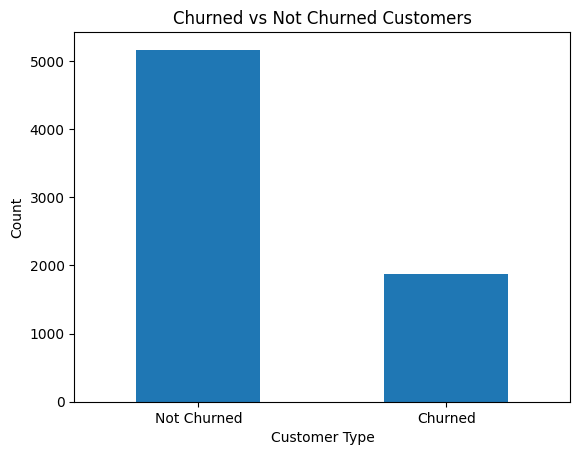

In [10]:
df["Churn"].value_counts().plot(
    kind="bar"
)

plt.xticks([0, 1], ["Not Churned", "Churned"], rotation=0)
plt.xlabel("Customer Type")
plt.ylabel("Count")
plt.title("Churned vs Not Churned Customers")

plt.show()

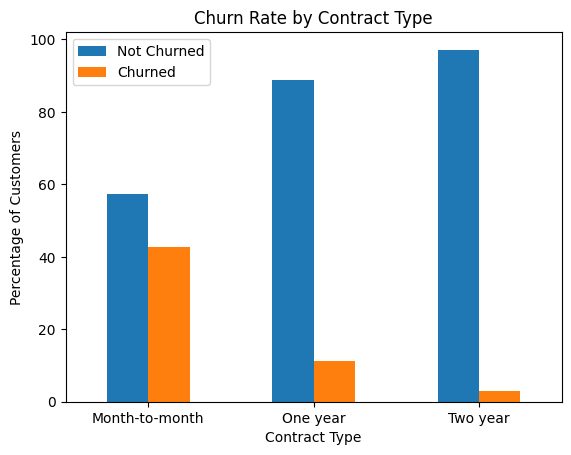

In [11]:
contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

contract_churn.plot(kind="bar")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.title("Churn Rate by Contract Type")
plt.legend(["Not Churned", "Churned"])
plt.xticks(rotation=0)
plt.show()

In [13]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5625, 19)
Testing Data: (1407, 19)


In [15]:
categorical_cols = X.select_dtypes(exclude="number").columns
numeric_cols = X.select_dtypes(include="number").columns

print("Numerical Columns:", list(numeric_cols))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

Numerical Columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [18]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [19]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 1 0 0 0 1 0 0 1 0]


In [20]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 72.56574271499645 %


In [21]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Churned", "Churned"]
))

              precision    recall  f1-score   support

 Not Churned       0.90      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



[[723 310]
 [ 76 298]]


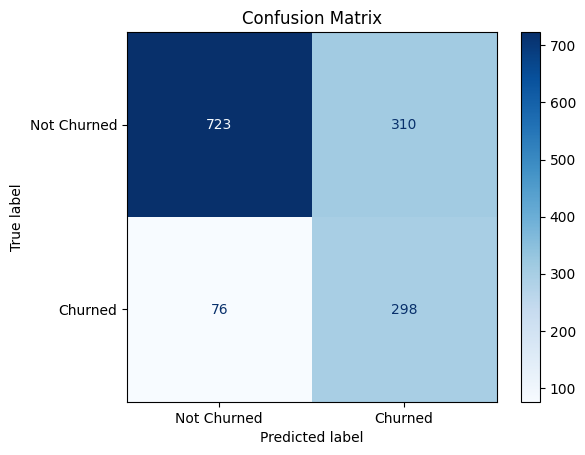

In [22]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(
    cm,
    display_labels=["Not Churned", "Churned"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [23]:
y_prob = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8351344145860403


In [24]:
rf_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred) * 100, "%")
print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]))

Random Forest Accuracy: 78.39374555792466 %
Random Forest ROC-AUC: 0.8120395918642033


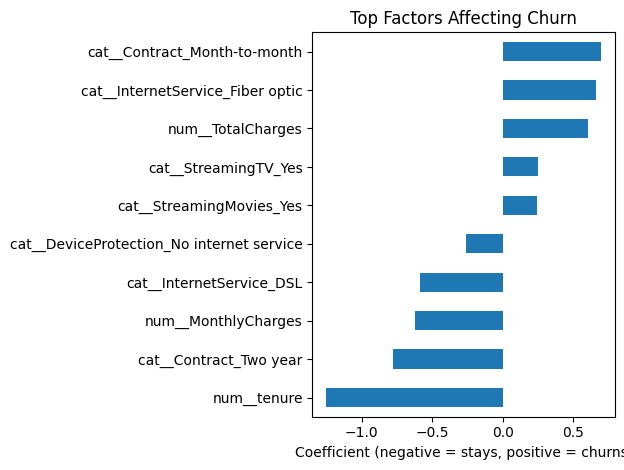

In [25]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]

importance = pd.Series(coefficients, index=feature_names).sort_values()
top_features = pd.concat([importance.head(5), importance.tail(5)])

top_features.plot(kind="barh")
plt.xlabel("Coefficient (negative = stays, positive = churns)")
plt.title("Top Factors Affecting Churn")
plt.tight_layout()
plt.show()

In [26]:
def predict_churn(customer):
    customer_df = pd.DataFrame([customer])
    prediction = model.predict(customer_df)[0]
    probability = model.predict_proba(customer_df)[0][1]
    if prediction == 1:
        return f"CUSTOMER WILL CHURN (Probability: {probability * 100:.1f}%)"
    else:
        return f"CUSTOMER WILL STAY (Churn Probability: {probability * 100:.1f}%)"

new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No",
    "Dependents": "No", "tenure": 3, "PhoneService": "Yes",
    "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 89.5, "TotalCharges": 268.5
}

result = predict_churn(new_customer)
print("Prediction:", result)

Prediction: CUSTOMER WILL CHURN (Probability: 90.0%)
